# Shipment routing across cost settings and decision methods

Run all cells to produce **two maps** for the same shipment:

1. Routes across the saved cost sensitivity runs.
2. SAA restricted/unrestricted and myopic restricted/unrestricted routes.

The default cost comparison includes the **entire cost grid**. Set
`COST_PARAMETER` to `'cost_flight'`, `'cost_ground'`, or
`'cost_penalty_incompatibility'` to vary one cost while holding the others
at their baseline values (or the overrides in `FIXED_COSTS`).
Equal cost-sweep route geometries share a color; the table identifies every
run belonging to each route. The method map retains all four case colors.

The default `ROUTE_STAGE = 'first_stage'` shows the planned route.
`'final'` shows active `keep + reassign` legs for `SCENARIO`. In the supplied
four method files, final active route sets agree across all scenarios while
first-stage routes differ. These are directed active leg sets,
so fractional flow can show branches. A change in keep/reassign labels alone
does not count as a route change. Omitted recourse scenarios contribute empty
routes, matching the sparse result format. No optimization is rerun.

Shared legs appear as adjacent colored strokes so overlapping routes remain
visible. Solid strokes indicate air; dashed strokes indicate ground.
Maps are displayed below and saved as PDF and PNG in `output/figures/shipment_routing/`.

In [1]:
from pathlib import Path
import sys
import json
import math
from itertools import combinations

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'src').is_dir() and (REPO_ROOT.parent / 'src').is_dir():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'src').is_dir():
    raise RuntimeError('Run from the repository root or notebooks directory.')
sys.path.insert(0, str(REPO_ROOT / 'src'))

SENSITIVITY_DIR = REPO_ROOT / 'src/output/sensitivity/results_500'
METHOD_DIR = REPO_ROOT / 'src/output/base_case_comparison'
CONFIG_PATH = SENSITIVITY_DIR / 'config.json'
OUTPUT_DIR = REPO_ROOT / 'output/figures/shipment_routing'

SHIPMENT_ID = None       # None selects a shipment with differences in both maps.
ROUTE_STAGE = 'first_stage'  # 'first_stage' or 'final'
SCENARIO = 0            # Zero-based; used only for final routes.
COST_PARAMETER = None  # Entire grid; or cost_flight, cost_ground, cost_penalty_incompatibility
FIXED_COSTS = {}         # Overrides for costs held fixed, e.g. {'cost_ground': 0.00027}
ACTIVE_THRESHOLD = 1e-6
FIGURE_WIDTH_INCHES = 6.5


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
from matplotlib.transforms import ScaledTranslation, Bbox
from IPython.display import display
from main import ProblemPreparer, SensitivityConfig
from plot_sensitivity_maps import first_stage_route, recourse_routes, jaccard_distance

# The script helpers select Agg; restore inline display after importing them.
%matplotlib inline
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 10, 'legend.fontsize': 10})

COST_FIELDS = ('cost_flight', 'cost_ground', 'cost_penalty_incompatibility')
METHOD_LABELS = {
    'integrated_restricted': 'SAA restricted',
    'integrated_unrestricted': 'SAA unrestricted',
    'myopic_restricted': 'Myopic restricted',
    'myopic_unrestricted': 'Myopic unrestricted',
}
if ROUTE_STAGE not in {'first_stage', 'final'}:
    raise ValueError("ROUTE_STAGE must be 'first_stage' or 'final'.")
if COST_PARAMETER is not None and COST_PARAMETER not in COST_FIELDS:
    raise ValueError(f'COST_PARAMETER must be one of {COST_FIELDS}, or None.')
if set(FIXED_COSTS) - set(COST_FIELDS):
    raise ValueError('FIXED_COSTS contains unknown cost fields.')
if COST_PARAMETER in FIXED_COSTS:
    raise ValueError('The varied COST_PARAMETER cannot also be held fixed.')
if not math.isfinite(ACTIVE_THRESHOLD) or ACTIVE_THRESHOLD < 0:
    raise ValueError('ACTIVE_THRESHOLD must be finite and nonnegative.')
if not isinstance(SCENARIO, int) or isinstance(SCENARIO, bool) or SCENARIO < 0:
    raise ValueError('SCENARIO must be a nonnegative integer.')

config = SensitivityConfig(CONFIG_PATH)
baseline_costs = config.data['base_parameters']
fixed_costs = dict(baseline_costs) | FIXED_COSTS

def retain_routes(result, path):
    """Keep only the selected stage/scenario to avoid storing the full sweep."""
    if ROUTE_STAGE == 'final' and SCENARIO >= result['num_scenarios']:
        raise ValueError(f'{path.name}: SCENARIO must be below {result["num_scenarios"]}.')
    has_solution = result.get('total_expected_cost', result.get('objective_value')) is not None
    if ROUTE_STAGE == 'first_stage':
        has_solution |= result.get('stages', {}).get('first_stage', {}).get('solution_count', 0) > 0
    metadata = {key: value for key, value in result.items()
                if key in {'parameters', 'run_index', 'case', 'seed', 'num_scenarios',
                           'status', 'restrict_first_stage', 'allow_air_leg_dropping'}}
    metadata['source'] = path.name
    metadata['available'] = has_solution
    metadata['routes'] = {
        sid: frozenset(first_stage_route(decisions, ACTIVE_THRESHOLD)
                       if ROUTE_STAGE == 'first_stage' else
                       recourse_routes(decisions, SCENARIO, ACTIVE_THRESHOLD)[0])
        for sid, decisions in result['decision_variables_by_shipment'].items()
    } if has_solution else {}
    return metadata

sensitivity_runs = []
paths = sorted(SENSITIVITY_DIR.glob('run_*.json'))
if not paths:
    raise FileNotFoundError(f'No run_*.json files in {SENSITIVITY_DIR}')
for path in paths:
    result = json.loads(path.read_text(encoding='utf-8'))
    if COST_PARAMETER is not None and any(
        not math.isclose(float(result['parameters'][field]), float(fixed_costs[field]),
                         rel_tol=1e-9, abs_tol=1e-12)
        for field in COST_FIELDS if field != COST_PARAMETER
    ):
        continue
    sensitivity_runs.append(retain_routes(result, path))
del result
sensitivity_runs.sort(key=lambda run: tuple(run['parameters'][field] for field in COST_FIELDS))
if len(sensitivity_runs) < 2:
    raise ValueError('Fewer than two cost settings match. Check COST_PARAMETER and FIXED_COSTS.')

method_runs = []
for case in METHOD_LABELS:
    path = METHOD_DIR / f'{case}.json'
    result = json.loads(path.read_text(encoding='utf-8'))
    if result.get('case', case) != case:
        raise ValueError(f'{path}: case does not match filename.')
    method_runs.append(retain_routes(result | {'case': case}, path))
del result
for runs in (sensitivity_runs, method_runs):
    if len({(run['seed'], run['num_scenarios']) for run in runs}) != 1:
        raise ValueError('Within each analysis, runs must use the same seed and scenario count.')
    if any(run['seed'] != config.data['seed'] for run in runs):
        raise ValueError('The coordinate config seed must match the saved results.')
print(f'Loaded {len(sensitivity_runs)} cost settings and {len(method_runs)} decision methods.')
print('Unavailable results:', [run['source'] for run in sensitivity_runs + method_runs
                               if not run['available']])


Loaded 96 cost settings and 4 decision methods.
Unavailable results: []


In [3]:
available_cost = [run for run in sensitivity_runs if run['available']]
available_methods = [run for run in method_runs if run['available']]
if len(available_cost) < 2 or len(available_methods) < 2:
    raise ValueError('At least two solved results are needed for each comparison.')
common_ids = sorted(set.intersection(*(set(run['routes']) for run in
                                     available_cost + available_methods)))
if not common_ids:
    raise ValueError('The two analyses have no common shipment IDs.')

def route_score(runs, sid):
    routes = [run['routes'][sid] for run in runs]
    distances = [jaccard_distance(a, b) for a, b in combinations(routes, 2)]
    return len(set(routes)), float(np.mean(distances))

ranking = []
for sid in common_ids:
    cost_count, cost_change = route_score(available_cost, sid)
    method_count, method_change = route_score(available_methods, sid)
    ranking.append({'shipment': sid, 'cost_routes': cost_count,
                    'method_routes': method_count, 'cost_change': cost_change,
                    'method_change': method_change,
                    'changes_in_both': cost_count > 1 and method_count > 1,
                    'combined_change': cost_change + method_change})
ranking = pd.DataFrame(ranking).sort_values(
    ['changes_in_both', 'combined_change', 'shipment'], ascending=[False, False, True])
shipment_id = ranking.iloc[0]['shipment'] if SHIPMENT_ID is None else str(SHIPMENT_ID)
if shipment_id not in common_ids:
    raise ValueError(f'Unknown or unavailable SHIPMENT_ID. Choose from: {", ".join(common_ids)}')
print(f'Selected shipment: {shipment_id}; stage: {ROUTE_STAGE}; scenario: {SCENARIO}')
print('Available shipment IDs:', ', '.join(common_ids))
if not ranking.set_index('shipment').loc[shipment_id, 'changes_in_both']:
    print('This shipment has identical routes in at least one comparison; see route counts below.')
display(ranking.head(10).reset_index(drop=True))

# Network metadata only; no path preprocessing or solver calls.
network = ProblemPreparer(config).prepare_network()
if shipment_id not in network.shipments:
    raise ValueError('Selected shipment is absent from the coordinate network. Check CONFIG_PATH.')
shipment = network.shipments[shipment_id]
print(f'Origin: {shipment.origin.node_id}; destination: {shipment.destination.node_id}')


Selected shipment: 23-0126-1; stage: first_stage; scenario: 0
Available shipment IDs: 22-0237, 22-0302, 22-0303, 22-0305, 22-0323, 22-0335, 22-0337, 22-0347, 22-0350, 22-0352, 22-0358, 22-0463, 23-0006, 23-0010, 23-0020, 23-0060, 23-0086, 23-0101, 23-0113, 23-0114, 23-0115, 23-0124, 23-0126-1, 23-0126-10, 23-0126-11, 23-0126-12, 23-0126-13, 23-0126-14, 23-0126-15, 23-0126-16, 23-0126-17, 23-0126-18, 23-0126-19, 23-0126-2, 23-0126-20, 23-0126-21, 23-0126-22, 23-0126-23, 23-0126-24, 23-0126-25, 23-0126-26, 23-0126-27, 23-0126-28, 23-0126-29, 23-0126-3, 23-0126-30, 23-0126-31, 23-0126-32, 23-0126-33, 23-0126-34, 23-0126-35, 23-0126-36, 23-0126-37, 23-0126-38, 23-0126-39, 23-0126-4, 23-0126-40, 23-0126-41, 23-0126-42, 23-0126-43, 23-0126-44, 23-0126-5, 23-0126-6, 23-0126-7, 23-0126-8, 23-0126-9, 23-0145, 23-0147, 23-0151, 23-0177, 23-0191, 23-0200, 23-0247, 23-0250, 23-0251, 23-0280, 23-0364, 23-0388, 23-0391, 24-0156, 24-0187, 24-0227, 24-0228, 24-0229, 24-0230, 24-0238, 25-0083
Origin: N

C:\Users\micah\OneDrive - Umich\humanitarian-multimodal\src\data_processing.py:83: UserWarning: Temporarily removed unique_carrier due to naming misalignment
  warnings.warn("Temporarily removed unique_carrier due to naming misalignment")
C:\Users\micah\OneDrive - Umich\humanitarian-multimodal\src\data_processing.py:83: UserWarning: Temporarily removed unique_carrier due to naming misalignment
  warnings.warn("Temporarily removed unique_carrier due to naming misalignment")
C:\Users\micah\OneDrive - Umich\humanitarian-multimodal\src\data_processing.py:278: UserWarning: Unknown airport codes found. Unknown Origins: ['DUESSELDORF', 'yyz'], Unknown Destinations: ['AYGR, PNP', 'Aden', 'NAN/Tonga', 'OUAGADOUGOU']. Rows with these codes will be dropped.
  warnings.warn(
C:\Users\micah\OneDrive - Umich\humanitarian-multimodal\src\data_processing.py:83: UserWarning: Temporarily removed unique_carrier due to naming misalignment
  warnings.warn("Temporarily removed unique_carrier due to naming mi

,shipment,cost_routes,method_routes,cost_change,method_change,changes_in_both,combined_change
0,23-0126-1,2,3,0.221053,0.766667,True,0.987719
1,23-0126-10,2,3,0.221053,0.766667,True,0.987719
2,23-0126-11,2,3,0.221053,0.766667,True,0.987719
3,23-0126-13,2,3,0.221053,0.766667,True,0.987719
4,23-0126-2,2,3,0.221053,0.766667,True,0.987719
5,23-0126-21,2,3,0.221053,0.766667,True,0.987719
6,23-0126-22,2,3,0.221053,0.766667,True,0.987719
7,23-0126-23,2,3,0.221053,0.766667,True,0.987719
8,23-0126-25,2,3,0.221053,0.766667,True,0.987719
9,23-0126-26,2,3,0.221053,0.766667,True,0.987719


In [4]:
# Describe route groups by the cost changes relative to the baseline.
COST_NAMES = {'cost_flight': 'air cost', 'cost_ground': 'ground cost',
              'cost_penalty_incompatibility': 'incompatibility penalty'}

def cost_distance(run, reference_costs):
    changes = [field for field in COST_FIELDS
               if not math.isclose(run['parameters'][field], reference_costs[field],
                                   rel_tol=1e-9, abs_tol=1e-12)]
    return (len(changes), sum(abs(run['parameters'][field] - reference_costs[field]) /
                             (abs(reference_costs[field]) or 1) for field in COST_FIELDS),
            run['run_index'])

reference_run = min(available_cost, key=lambda run: cost_distance(run, baseline_costs))
reference_costs = reference_run['parameters']
reference_route = reference_run['routes'][shipment_id]
reference_is_baseline = cost_distance(reference_run, baseline_costs)[0] == 0
cost_group_examples = {}
for run in available_cost:
    route = run['routes'][shipment_id]
    if route not in cost_group_examples or cost_distance(run, reference_costs) < cost_distance(
        cost_group_examples[route], reference_costs
    ):
        cost_group_examples[route] = run

cost_groups = {}
for route, example in cost_group_examples.items():
    if route == reference_route:
        label = 'Baseline routing' if reference_is_baseline else 'Reference routing'
    else:
        changes = [field for field in COST_FIELDS
                   if not math.isclose(example['parameters'][field], reference_costs[field],
                                       rel_tol=1e-9, abs_tol=1e-12)]
        label = ', '.join(('Higher ' if example['parameters'][field] > reference_costs[field]
                           else 'Lower ') + COST_NAMES[field] for field in changes)
    # Include the representative costs if two distinct geometries receive the
    # same directional description.
    if label in cost_groups.values():
        label += ' (' + ', '.join(f'{example["parameters"][field]:g}' for field in changes) + ')'
    cost_groups[route] = label
cost_rows = []
for run in sensitivity_runs:
    route = run['routes'].get(shipment_id)
    if route is None:
        label = 'Unavailable'
    else:
        label = cost_groups[route]
    cost_rows.append({'run': run['run_index'], **run['parameters'], 'route': label,
                      'air_legs': None if route is None else sum(leg[2] == 'air' for leg in route),
                      'ground_legs': None if route is None else sum(leg[2] == 'ground' for leg in route)})
cost_table = pd.DataFrame(cost_rows)
display(cost_table)
method_table = pd.DataFrame([
    {'method': METHOD_LABELS[run['case']], 'status': run['status'],
     'available': run['available'], 'allow_air_leg_dropping': run.get('allow_air_leg_dropping'),
     'air_legs': None if not run['available'] else sum(leg[2] == 'air' for leg in run['routes'][shipment_id]),
     'ground_legs': None if not run['available'] else sum(leg[2] == 'ground' for leg in run['routes'][shipment_id])}
    for run in method_runs
])
display(method_table)
# The saved myopic unrestricted case can allow air-leg dropping. The table
# exposes this formulation difference instead of assuming all cases match.


,run,cost_flight,cost_ground,cost_penalty_incompatibility,route,air_legs,ground_legs
0,0,0.000385,0.000068,0.0,Baseline routing,1,1
1,1,0.000385,0.000068,10.0,Baseline routing,1,1
2,2,0.000385,0.000068,100.0,Baseline routing,1,1
3,3,0.000385,0.000068,500.0,Baseline routing,1,1
4,4,0.000385,0.000068,1000.0,Baseline routing,1,1
...,...,...,...,...,...,...,...
91,91,0.007700,0.001350,10.0,Baseline routing,1,1
92,92,0.007700,0.001350,100.0,Baseline routing,1,1
93,93,0.007700,0.001350,500.0,Baseline routing,1,1
94,94,0.007700,0.001350,1000.0,Baseline routing,1,1


,method,status,available,allow_air_leg_dropping,air_legs,ground_legs
0,SAA restricted,2,True,False,1,9
1,SAA unrestricted,2,True,False,1,1
2,Myopic restricted,2,True,False,1,1
3,Myopic unrestricted,2,True,True,2,3


In [5]:
from route_map_layout import MAP_FIGURE_SIZE, apply_map_layout

def draw_comparison(entries, title, subtitle, stem):
    """Render one map; entries contain (legend label, active directed legs, color)."""
    all_legs = set().union(*(route for _, route, _ in entries))
    endpoint_ids = {shipment.origin.node_id, shipment.destination.node_id}
    node_ids = sorted({node for leg in all_legs for node in leg[:2]} | endpoint_ids)
    missing = set(node_ids) - network.nodes.keys()
    if missing:
        raise ValueError(f'Route nodes lack coordinates: {sorted(missing)}')
    fig = plt.figure(figsize=MAP_FIGURE_SIZE)
    ax = fig.add_subplot(111, projection=ccrs.Robinson(central_longitude=-20))
    ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='lightgray', edgecolor='black', linewidth=0.35)
    ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='#e6f7ff')
    ax.add_feature(cfeature.COASTLINE.with_scale('110m'), linewidth=0.4)
    ax.add_feature(cfeature.BORDERS.with_scale('110m'), linestyle=':', linewidth=0.35, alpha=0.6)
    nodes = [network.nodes[node] for node in node_ids]
    lons = [node.longitude for node in nodes]
    lats = [node.latitude for node in nodes]
    lon_span, lat_span = max(lons) - min(lons), max(lats) - min(lats)
    if lon_span > 180:
        ax.set_global()
    else:
        # Leave room for great-circle arcs without making north/south maps narrow.
        py = max(25, min(40, lat_span * 0.5))
        px = max(5, lon_span * 0.08, (lat_span + 2 * py) * 0.45 - lon_span / 2)
        ax.set_extent((max(-180, min(lons) - px), min(180, max(lons) + px),
                       max(-85, min(lats) - py), min(85, max(lats) + py)), crs=ccrs.PlateCarree())
    # ax.set_title(f'{title}\nShipment {shipment_id} | ' +
    #              ('First-stage route' if ROUTE_STAGE == 'first_stage' else f'Final route, scenario {SCENARIO}') +
    #              f'\n{subtitle}', pad=10)
    handles = [Line2D([0], [0], color=color, lw=2, label=label) for label, _, color in entries]
    handles += [
        Line2D([0], [0], color='black', lw=1.5, label='Air leg'),
        Line2D([0], [0], color='black', lw=1.5, linestyle='--', label='Ground leg'),
        Line2D([0], [0], color='darkred', marker='^', linestyle='None', label='Airport'),
        Line2D([0], [0], color='dimgray', marker='o', linestyle='None', label='Transfer point'),
        Line2D([0], [0], color='#16a34a', marker='*', linestyle='None', label='Shipment origin'),
        Line2D([0], [0], color='#dc2626', marker='*', linestyle='None', label='Shipment destination'),
    ]
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.04),
              ncols=3, frameon=True, fontsize=10)
    apply_map_layout(ax)
    fig.canvas.draw()
    geodetic_transform = ccrs.Geodetic()._as_mpl_transform(ax)
    point_transform = ccrs.PlateCarree()._as_mpl_transform(ax)
    for origin, destination, mode in sorted(all_legs):
        a, b = network.nodes[origin], network.nodes[destination]
        owners = [color for _, route, color in entries if (origin, destination, mode) in route]
        delta = point_transform.transform((b.longitude, b.latitude)) - point_transform.transform((a.longitude, a.latitude))
        norm = np.linalg.norm(delta)
        perpendicular = np.array([-delta[1], delta[0]]) / norm if norm else np.array([0., 1.])
        for index, color in enumerate(owners):
            offset_points = (index - (len(owners) - 1) / 2) * 1.5
            dx, dy = perpendicular * offset_points / 72
            ax.plot([a.longitude, b.longitude], [a.latitude, b.latitude],
                    color=color, lw=1.35, linestyle='--' if mode == 'ground' else '-',
                    alpha=0.9, transform=geodetic_transform + ScaledTranslation(dx, dy, fig.dpi_scale_trans),
                    zorder=3)
    for node in nodes:
        if node.node_id in endpoint_ids:
            color = '#16a34a' if node.node_id == shipment.origin.node_id else '#dc2626'
            marker, size = '*', 65
        elif node.connection_type == 'air':
            color, marker, size = 'darkred', '^', 20
        else:
            color, marker, size = 'dimgray', 'o', 14
        ax.scatter(node.longitude, node.latitude, color=color, marker=marker, s=size,
                   edgecolor='black' if marker == '*' else None, linewidth=0.4,
                   # Endpoint stars sit above airport/transfer symbols and labels.
                   transform=ccrs.PlateCarree(),
                   zorder=100 if node.node_id in endpoint_ids else 7)
    airport_label_nodes = [node for node in nodes if node.connection_type == 'air']
    # Place each airport label at the closest available offset.  The display-space
    # collision check protects all map symbols and labels already placed.
    airport_transform = ccrs.PlateCarree()._as_mpl_transform(ax)
    label_offsets = (
        (5, 5), (5, -5), (-5, 5), (-5, -5), (8, 0), (-8, 0), (0, 8), (0, -8),
        (10, 10), (10, -10), (-10, 10), (-10, -10), (14, 0), (-14, 0),
    )
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    icon_boxes = []
    for node_id in node_ids:
        node_x, node_y = airport_transform.transform((network.nodes[node_id].longitude, network.nodes[node_id].latitude))
        icon_boxes.append(Bbox.from_bounds(node_x - 6, node_y - 6, 12, 12))
    occupied_label_boxes = []
    for node in airport_label_nodes:
        chosen = None
        for offset_x, offset_y in label_offsets:
            label = ax.annotate(
                node.node_id, (node.longitude, node.latitude), xycoords=airport_transform,
                xytext=(offset_x, offset_y), textcoords='offset points',
                fontsize=5, color='darkred',
                ha='left' if offset_x >= 0 else 'right',
                va='bottom' if offset_y >= 0 else 'top', zorder=6,
            )
            fig.canvas.draw()
            label_box = label.get_window_extent(renderer)
            if not any(label_box.overlaps(box) for box in (*icon_boxes, *occupied_label_boxes)):
                chosen = (label, offset_x, offset_y, label_box)
                break
            label.remove()
        if chosen is None:
            # A dense airport cluster can exhaust the close candidates; retain a readable fallback.
            offset_x, offset_y = 18, 18
            label = ax.annotate(
                node.node_id, (node.longitude, node.latitude), xycoords=airport_transform,
                xytext=(offset_x, offset_y), textcoords='offset points',
                fontsize=5, color='darkred', ha='left', va='bottom', zorder=6,
            )
            fig.canvas.draw()
            chosen = (label, offset_x, offset_y, label.get_window_extent(renderer))
        label, offset_x, offset_y, label_box = chosen
        ax.annotate(
            '', (node.longitude, node.latitude), xycoords=airport_transform,
            xytext=(offset_x, offset_y), textcoords='offset points',
            arrowprops={'arrowstyle': '-', 'color': 'darkred', 'lw': 0.35, 'shrinkA': 0, 'shrinkB': 2},
            zorder=5.5,
        )
        occupied_label_boxes.append(label_box.expanded(1.08, 1.18))

    if len({route for _, route, _ in entries}) == 1:
        print(f'{title}: all available settings have the same active route.')
    if any(not route for _, route, _ in entries):
        print(f'{title}: a solved result has no active legs for the selected stage/scenario.')
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    suffix = 'first-stage' if ROUTE_STAGE == 'first_stage' else f'final-scenario-{SCENARIO}'
    for extension in ('pdf', 'png'):
        path = OUTPUT_DIR / f'{stem}-{shipment_id}-{suffix}.{extension}'
        fig.savefig(path, dpi=300, bbox_inches='tight')
        print(f'Saved {path.relative_to(REPO_ROOT)}')
    plt.show()
    plt.close(fig)
    return fig


## Map 1: Cost variation

The printed comparison below states which costs changed and which active legs
were added or removed relative to the baseline. Each description uses the closest
saved cost setting producing that routing; the table above lists all matching runs.
The legend uses these descriptions instead of numbered routes.

Baseline: air cost=0.00077, ground cost=0.000135, incompatibility penalty=100
Active legs: DTW -> FCO (air); NP120_ORD_O -> DTW (ground)

Higher ground cost: ground cost 0.000135 -> 0.00135. Held fixed: air cost=0.00077, incompatibility penalty=100.
  Removed legs: DTW -> FCO (air); NP120_ORD_O -> DTW (ground)
  Added legs: NP120_ORD_O -> ORD (ground); ORD -> FCO (air)
Saved output\figures\shipment_routing\cost-variation-all-costs-23-0126-1-first-stage.pdf
Saved output\figures\shipment_routing\cost-variation-all-costs-23-0126-1-first-stage.png


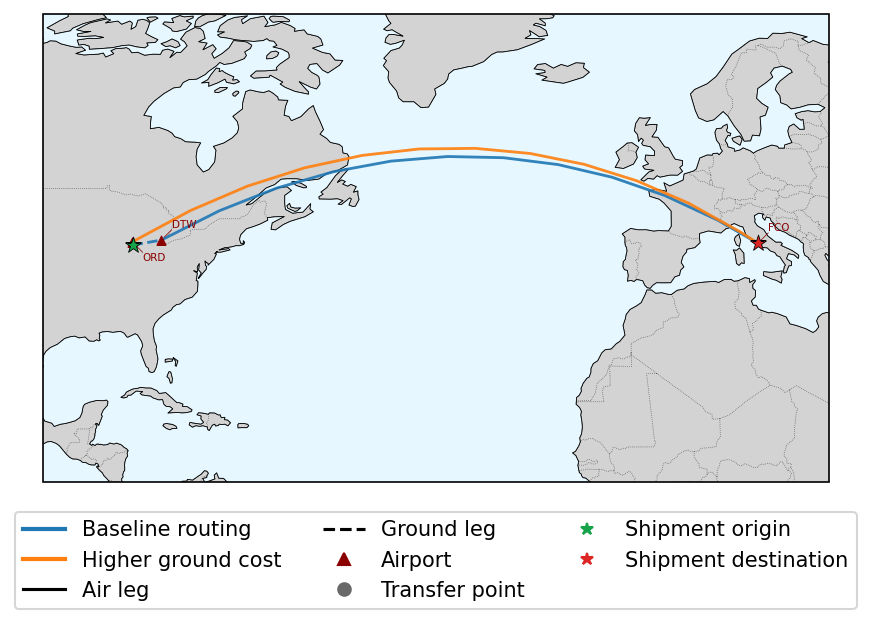

In [6]:
def describe_legs(legs):
    return '; '.join(f'{origin} -> {destination} ({mode})'
                     for origin, destination, mode in sorted(legs)) or 'none'

reference_name = 'Baseline' if reference_is_baseline else 'Reference (baseline setting unavailable)'
print(f'{reference_name}: ' + ', '.join(f'{COST_NAMES[field]}={reference_costs[field]:g}'
                                       for field in COST_FIELDS))
print('Active legs: ' + describe_legs(reference_route))
for route, label in cost_groups.items():
    if route == reference_route:
        continue
    example_costs = cost_group_examples[route]['parameters']
    changed = [field for field in COST_FIELDS
               if not math.isclose(example_costs[field], reference_costs[field],
                                   rel_tol=1e-9, abs_tol=1e-12)]
    changes = ', '.join(f'{COST_NAMES[field]} {reference_costs[field]:g} -> {example_costs[field]:g}'
                        for field in changed)
    fixed = ', '.join(f'{COST_NAMES[field]}={reference_costs[field]:g}'
                      for field in COST_FIELDS if field not in changed)
    print(f'\n{label}: {changes}.' + (f' Held fixed: {fixed}.' if fixed else ''))
    print('  Removed legs: ' + describe_legs(reference_route - route))
    print('  Added legs: ' + describe_legs(route - reference_route))

palette = plt.get_cmap('tab10' if len(cost_groups) <= 10 else 'turbo')
cost_entries = []
for index, (route, label) in enumerate(cost_groups.items()):
    color = palette(index) if len(cost_groups) <= 10 else palette(index / max(1, len(cost_groups) - 1))
    cost_entries.append((label, route, color))
if COST_PARAMETER is None:
    subtitle = f'Entire cost grid | {len(sensitivity_runs)} settings, {len(cost_groups)} routes'
else:
    fixed_text = '\n'.join(f'{COST_NAMES[field].capitalize()}={fixed_costs[field]:g}'
                           for field in COST_FIELDS if field != COST_PARAMETER)
    subtitle = f'{COST_NAMES[COST_PARAMETER].capitalize()} sweep\n{fixed_text}'
cost_figure = draw_comparison(cost_entries, 'Shipment routing across cost settings', subtitle,
                             f'cost-variation-{COST_PARAMETER or "all-costs"}')


## Map 2: SAA and myopic methods

The integrated optimization result files are labeled **SAA** here.
Four colors preserve restricted/unrestricted method membership even when
two methods use identical routes. Results without an incumbent are listed
in the tables and excluded from the route overlay.

Saved output\figures\shipment_routing\saa-vs-myopic-23-0126-1-first-stage.pdf
Saved output\figures\shipment_routing\saa-vs-myopic-23-0126-1-first-stage.png


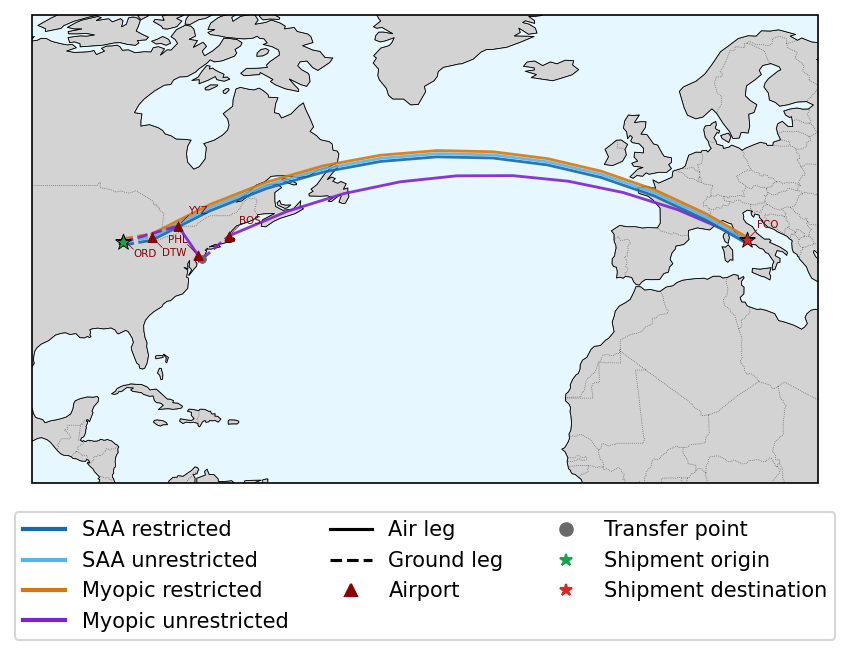

In [7]:
method_colors = ['#1769aa', '#56b4e9', '#d97706', '#7e22ce']
method_entries = [
    (METHOD_LABELS[run['case']], run['routes'][shipment_id], color)
    for run, color in zip(method_runs, method_colors, strict=True) if run['available']
]
method_figure = draw_comparison(method_entries, 'Shipment routing by decision method',
                                'SAA and myopic | restricted and unrestricted', 'saa-vs-myopic')
